# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

A continuación se exploran los tres datasets: orders, catalog y marketing. Usando .head() y .info()

In [3]:
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [4]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [5]:
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [6]:
catalog.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


In [7]:
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


In [8]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


In [9]:
#  Diagnosticar qué tan completo está el dataset Orders:
orders.isna().sum()

id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64

In [10]:
#  El dataset Orders tiene 25100 registros, hallar la importancia significativa de los nulls:
orders.isna().sum() / len(orders) *  100

id_pedido             0.000000
id_usuario            0.000000
fecha_hora_pedido     0.000000
pais                  1.195219
dispositivo           0.079681
fuente_referencia     0.119522
nombre_producto       0.119522
categoria_producto    0.318725
cantidad              0.199203
precio_unitario       0.199203
monto_descuento       0.199203
monto_total           0.000000
dtype: float64

In [11]:
# Sumar el total de nulls en Orders:
orders.isna().sum().sum() 

610

La importancia significativa de los nulls en Orders es menor al 1%, en total el dataset tiene 610 nulls.

In [12]:
#  Diagnosticar qué tan completo está el dataset Catalog:
catalog.isna().sum()

nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64

El dataset de Catalog no tiene faltantes (nulls)

In [13]:
#  Diagnosticar qué tan completo está el dataset Marketing:
marketing.isna().sum()

fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

In [14]:
#  El dataset Marketing tiene 1620 registros, hallar la importancia significativa de los nulls:
marketing.isna().sum() / len(marketing) *  100

fecha         0.000000
pais          0.000000
id_campaña    0.000000
canal         6.234568
gasto         0.000000
dtype: float64

In [15]:
# Sumar el total de nulls en Marketing:
marketing.isna().sum().sum() 

101

La importancia significativa de los nulls en Marketing es menor al 7%, en total el dataset tiene 101 nulls.

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas 

---

Revisando de forma general los tres datasets se encuentra que:

ORDERS: 
•	Fecha hora pedido esta como Object y debe ser Datetime.
•	Cantidad esta como Float porque tiene 50 valores Nan.
•	Nulls en las columnas: país, dispositivo, fuente de referencia, nombre producto, categoría producto, cantidad, precio unitario y monto descuento.

CATALOG
•	No hay nulls y todos los dtype están correctos.

MARKETING
•	Fecha esta como Object y debe ser Datetime.
•	Nulls en la columna: Canal.

In [16]:
# Convertir Fecha hora pedido al formato Datetime, dataset orders:
orders["fecha_hora_pedido"] = pd.to_datetime(orders["fecha_hora_pedido"])

In [17]:
# Verificación de cambio de la columna fecha en orders:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                24800 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25020 non-null  object        
 8   cantidad            25050 non-null  float64       
 9   precio_unitario     25050 non-null  float64       
 10  monto_descuento     25050 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


In [18]:
# Convertir Fecha al formato Datetime,  dataset Marketing:
marketing["fecha"] = pd.to_datetime(marketing["fecha"])

In [19]:
# Verificación de cambio de la columna fecha hora pedido en orders:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                24800 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25020 non-null  object        
 8   cantidad            25050 non-null  float64       
 9   precio_unitario     25050 non-null  float64       
 10  monto_descuento     25050 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


In [20]:
# Verificación de cambio de la columna fecha en marketing:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1519 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB


In [21]:
# Revisión de duplicados en orders:
orders.duplicated().sum()

100

In [22]:
# Porcentaje que representan los duplicados en orders:
orders.duplicated().sum() / len(orders) * 100

0.398406374501992

En el dataset orders se encontraron 100 filas duplicadas equivalentes al 0.39%.

In [23]:
# Filas marcadas como duplicadas en orders:
orders[orders.duplicated()]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
25000,order_22936,user_4028,2025-06-30,Argentina,desktop,social,Vacuum-Pro-Black,Hogar,2.0,41.91,10.0,73.82
25001,order_13710,user_4466,2025-03-20,Mexico,desktop,social,Jacket-Winter-M,Moda,2.0,483.32,0.0,966.65
25002,order_14562,user_6590,2025-03-23,Mexico,mobile,paid_search,Tablet-Standard-64GB,Electronica,1.0,481.96,5.0,476.96
25003,order_11537,user_3115,2025-03-08,Argentina,desktop,organic,Vacuum-Pro-Black,Hogar,1.0,147.20,5.0,142.20
25004,order_4533,user_7944,2025-02-16,Argentina,mobile,organic,Blender-XL-Red,Hogar,1.0,176.91,5.0,171.91
...,...,...,...,...,...,...,...,...,...,...,...,...
25095,order_3913,user_380,2025-02-18,Argentina,desktop,paid_search,Phone-Pro-128GB,Electronica,1.0,82.28,0.0,82.28
25096,order_23405,user_7833,2025-04-04,Colombia,mobile,paid_search,Phone-Pro-128GB,Electronica,2.0,99.25,5.0,193.50
25097,order_5615,user_5417,2025-05-13,Colombia,desktop,social,Blender-XL-Red,Hogar,2.0,450.35,5.0,895.69
25098,order_812,user_1530,2025-03-31,Argentina,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,167.32,10.0,157.32


In [24]:
orders[orders["id_pedido"] == "order_22936"]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
22936,order_22936,user_4028,2025-06-30,Argentina,desktop,social,Vacuum-Pro-Black,Hogar,2.0,41.91,10.0,73.82
25000,order_22936,user_4028,2025-06-30,Argentina,desktop,social,Vacuum-Pro-Black,Hogar,2.0,41.91,10.0,73.82


Se verifica manualmente uno de los casos para confirmar que eran copias exactas y no coincidencias. Celda de código con el filtro orders[orders["id_pedido"] == "order_22936"]

In [25]:
# Hay id_pedido repetidos que NO sean duplicados exactos?
repetidos_id = orders[orders.duplicated(subset="id_pedido", keep=False)]
exactos = orders[orders.duplicated(keep=False)]
print(len(repetidos_id), len(exactos))
# Si ambos números son iguales, todos los id repetidos son copias exactas

200 200


In [26]:
# Verificación que la eliminación quedó bien:
orders = orders.drop_duplicates().reset_index(drop=True)
print(orders["id_pedido"].is_unique)   # debería dar True
print(len(orders))                     

True
25000


In [27]:
# Verificación de eliminación de duplicados en orders:
orders.duplicated().sum()

0

Se detectaron y eliminaron 100 filas duplicadas exactas en orders (25100 → 25000). Se verificó que todos los id_pedido repetidos correspondían a copias idénticas y que, tras la limpieza, id_pedido es único. Si dejamos el duplicado contará dos veces el mismo pedido, inflaría ingresos, cantidad de pedidos, ticket promedio, etc. Además, id_pedido debería ser único por pedido, así que una repetición traeria consigo errores futuros por lo tanto se decidio eliminarlos.

In [28]:
# Revisión de duplicados en catalog:
catalog.duplicated().sum()

0

El dataset catalog no tiene duplicados.

In [29]:
# Revisión de duplicados en marketing:
marketing.duplicated().sum()

0

El dataset marketing no tiene duplicados.

In [30]:
# Porcentaje que representan los 50 nulls en la columna cantidad del dataset orders:
orders["cantidad"].isna().sum() / len(orders) * 100

0.2

In [31]:
# Inspección filas nulls columna cantidad dataset orders:
orders[orders["cantidad"].isna()]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
74,order_74,user_6172,2025-01-15,Argentina,desktop,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,595.85
75,order_75,user_6588,2025-06-19,Colombia,mobile,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,458.15
76,order_76,user_3193,2025-03-17,Argentina,mobile,paid_search,Laptop-Gaming-16GB,NaN,NaN,NaN,NaN,319.75
77,order_77,user_775,2025-06-24,Argentina,desktop,social,Vacuum-Pro-Black,NaN,NaN,NaN,NaN,227.55
78,order_78,user_2702,2025-03-19,Argentina,desktop,paid_search,Phone-Pro-128GB,NaN,NaN,NaN,NaN,432.39
79,order_79,user_6438,2025-03-22,Colombia,desktop,paid_search,Sneakers-Urban-42,NaN,NaN,NaN,NaN,527.15
80,order_80,user_6790,2025-01-03,Mexico,desktop,organic,Vacuum-Pro-Black,NaN,NaN,NaN,NaN,711.18
81,order_81,user_232,2025-05-16,Mexico,mobile,paid_search,Tablet-Standard-64GB,NaN,NaN,NaN,NaN,41.08
82,order_82,user_5665,2025-02-07,Colombia,mobile,paid_search,Sneakers-Urban-42,NaN,NaN,NaN,NaN,431.55
83,order_83,user_5225,2025-04-25,Argentina,mobile,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,279.35


Aunque no se tiene información sobre cantidad o precio unitario, no se procede con su eliminación por que estas filas contiene información que es útil como monto total, id pedido,  etc. Por ello no se eliminaran.

In [32]:
# Verifica que el patrón sea consistente. Confirma que los 50 nulls son siempre los mismos en las cuatro columnas:
cols = ["categoria_producto", "cantidad", "precio_unitario", "monto_descuento"]
print(orders[cols].isna().all(axis=1).sum())   # debería dar 50
print(orders["monto_total"].isna().sum())      # debería dar 0

50
0


50: las columnas categoria_producto, cantidad, precio_unitario y monto_descuento están vacías juntas en las mismas 50 filas. Es decir, no son nulls aislados ni dispersos, sino un bloque completo de información faltante.
0: ninguna de esas filas tiene monto_total nulo, así que conservan el dato más importante para el reporte: el ingreso.

In [33]:
# Se marcan las filas como "detalle incompleto":
orders["detalle_incompleto"] = orders["cantidad"].isna()

In [34]:
# Verificación si podemos recuperar la categoria producto:
print(orders.groupby("nombre_producto")["categoria_producto"].nunique().max())  # debería dar 1

1


In [35]:
# Si da 1, rellenar la categoría con un mapeo seguro:
mapa = orders.dropna(subset=["categoria_producto"]).drop_duplicates("nombre_producto").set_index("nombre_producto")["categoria_producto"]
orders["categoria_producto"] = orders["categoria_producto"].fillna(orders["nombre_producto"].map(mapa))

In [36]:
# Revisión:
print(orders["categoria_producto"].isna().sum())

30


Como su resultado es un número mayor a cero, se verificara porque esas filas no se le pudo reemplazar la categoria de producto.

In [37]:
# Diagnostico de las filas que no se les pudo reemplazar la categoria producto:
pendientes = orders[orders["categoria_producto"].isna()]

print(pendientes["nombre_producto"].isna().sum())                # ¿también sin producto?
print(pendientes["nombre_producto"].value_counts(dropna=False))  # ¿qué productos son?
print(pendientes["detalle_incompleto"].sum())                    # ¿cuántas son del bloque de 50?
print(pendientes[["cantidad", "precio_unitario", "monto_descuento"]].isna().sum())

30
NaN    30
Name: nombre_producto, dtype: int64
0
cantidad           0
precio_unitario    0
monto_descuento    0
dtype: int64


El resultado nos dice que las 30 filas no se pudieron reemplazar, ya que sin el nombre producto no hay forma de deducir la categoria. Estas 30 filas no pertenece al bloque que vimos en los pasos anteriores (los 50 Nan). Estas 30 filas si tiene cantidad, precio unitario y monto descuento. Por tal motivo, se mantiene sin imputar la categoria.

In [38]:
# Etiquetar explícitamente la categoría faltante:
orders["categoria_producto"] = orders["categoria_producto"].fillna("Sin dato")
orders["nombre_producto"] = orders["nombre_producto"].fillna("Sin dato")

In [39]:
# Verificar que su monto_total es consistente:
p = orders[orders["nombre_producto"] == "Sin dato"]
calc = p["cantidad"] * p["precio_unitario"] - p["monto_descuento"]
print((abs(calc - p["monto_total"]) < 0.01).sum())   # debería dar 30

30


30 pedidos sin nombre_producto ni categoria_producto; no es posible recuperarlos desde otras columnas. Sin embargo, se conservan  porque tienen monto y detalle numérico válido y se etiquetan como ‘Sin dato’ en los análisis por categoría.

In [40]:
# Porcentaje que representan los 101 nulls en la columna canal del dataset marketing:
marketing["canal"].isna().sum() / len(marketing) * 100

6.234567901234568

In [41]:
# Inspección filas nulls columna canal dataset marketing:
marketing[marketing["canal"].isna()]

,fecha,pais,id_campaña,canal,gasto
98,2025-01-11,Argentina,social_Argentina,NaN,849.70
99,2025-01-12,Mexico,organic_Mexico,NaN,2033.56
100,2025-01-12,Mexico,paid_search_Mexico,NaN,1260.65
101,2025-01-12,Mexico,social_Mexico,NaN,1660.90
102,2025-01-12,Colombia,organic_Colombia,NaN,1819.27
...,...,...,...,...,...
194,2025-01-22,Colombia,social_Colombia,NaN,772.46
195,2025-01-22,Argentina,organic_Argentina,NaN,1562.61
196,2025-01-22,Argentina,paid_search_Argentina,NaN,644.34
197,2025-01-22,Argentina,social_Argentina,NaN,2544.66


In [42]:
# Rellena solo los NaN, usando todo lo que está antes del último "_":
marketing['canal'] = marketing['canal'].fillna(marketing['id_campaña'].str.rsplit('_', n=1).str[0])

In [43]:
# Inspección relleno de filas NaN columna canal dataset marketing:
marketing[marketing["canal"].isna()]

,fecha,pais,id_campaña,canal,gasto


In [44]:
# Verificación Nan en Marketing:
marketing.info()
print(marketing.isna().sum())
print(marketing.duplicated().sum())
print(marketing.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1620 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB
fecha         0
pais          0
id_campaña    0
canal         0
gasto         0
dtype: int64
0
            gasto
count  1620.00000
mean   1772.74292
std     734.43294
min     501.11000
25%    1128.03000
50%    1782.42500
75%    2420.68500
max    2999.36000


Las filas que estaban con NaN en la columna Canal del dataset Marketing, fueron rellenadas tomando la información de id_campaña.

In [45]:
# Verificación de valores negativos o iguales a cero columna cantidad dataset orders:
orders[orders["cantidad"] <= 0]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,detalle_incompleto
266,order_266,user_7011,2025-03-13,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62,False
267,order_267,user_1087,2025-05-07,NaN,desktop,social,Phone-Pro-128GB,Electronica,-1.0,43.50,5.0,-38.50,False
268,order_268,user_84,2025-02-19,NaN,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65,False
269,order_269,user_3323,2025-05-25,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-1.0,423.53,0.0,-423.53,False


In [46]:
# Dimensiona el problema:
print((orders["cantidad"] < 0).sum())    # ¿cuántas negativas hay?
print((orders["cantidad"] == 0).sum())   # ¿hay ceros?
print(orders[orders["cantidad"] < 0][["id_pedido", "pais", "nombre_producto", "monto_total"]])
print(orders[orders["cantidad"] < 0]["pais"].isna().sum())   # ¿todas sin país?

4
0
     id_pedido pais  nombre_producto  monto_total
266  order_266  NaN  Phone-Pro-128GB      -192.62
267  order_267  NaN  Phone-Pro-128GB       -38.50
268  order_268  NaN  Phone-Pro-128GB      -492.65
269  order_269  NaN  Phone-Pro-128GB      -423.53
4


In [47]:
# Se mira más al detalle los negativos, user_7011:
orders[orders["id_usuario"]=="user_7011"]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,detalle_incompleto
266,order_266,user_7011,2025-03-13,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62,False
10343,order_10343,user_7011,2025-03-14,Colombia,desktop,organic,Phone-Pro-128GB,Electronica,2.0,356.83,0.0,713.67,False


In [48]:
# Se mira más al detalle los negativos, user_1087:
orders[orders["id_usuario"]=="user_1087"]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,detalle_incompleto
267,order_267,user_1087,2025-05-07,NaN,desktop,social,Phone-Pro-128GB,Electronica,-1.0,43.50,5.0,-38.50,False
3862,order_3862,user_1087,2025-04-21,Mexico,desktop,paid_search,Laptop-Gaming-16GB,Electronica,1.0,413.39,10.0,403.39,False
8231,order_8231,user_1087,2025-03-04,Mexico,desktop,paid_search,Sneakers-Urban-42,Moda,1.0,73.92,0.0,73.92,False
13314,order_13314,user_1087,2025-06-23,Mexico,desktop,social,Laptop-Gaming-16GB,Electronica,2.0,392.18,0.0,784.37,False
24216,order_24216,user_1087,2025-06-06,Mexico,desktop,paid_search,Vacuum-Pro-Black,Hogar,1.0,352.83,15.0,337.83,False
24243,order_24243,user_1087,2025-05-27,Mexico,desktop,paid_search,Blender-XL-Red,Hogar,2.0,251.30,0.0,502.60,False


In [49]:
# Se mira más al detalle los negativos, user_84:
orders[orders["id_usuario"]=="user_84"]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,detalle_incompleto
268,order_268,user_84,2025-02-19,NaN,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65,False
2597,order_2597,user_84,2025-04-05,colombia,desktop,paid_search,Vacuum-Pro-Black,Hogar,2.0,428.90,0.0,857.81,False
11010,order_11010,user_84,2025-06-10,Colombia,desktop,organic,Sneakers-Urban-42,Moda,2.0,34.14,15.0,53.28,False
20524,order_20524,user_84,2025-06-04,Colombia,desktop,social,Sneakers-Urban-42,Moda,1.0,495.30,0.0,495.30,False
23096,order_23096,user_84,2025-03-12,Colombia,desktop,social,Phone-Pro-128GB,Electronica,2.0,258.82,0.0,517.63,False


In [50]:
# Se mira más al detalle los negativos, user_3323:
orders[orders["id_usuario"]=="user_3323"]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,detalle_incompleto
269,order_269,user_3323,2025-05-25,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-1.0,423.53,0.0,-423.53,False
7353,order_7353,user_3323,2025-01-06,colombia,desktop,organic,Tablet-Standard-64GB,Electronica,2.0,234.67,5.0,464.35,False
7742,order_7742,user_3323,2025-01-15,Colombia,desktop,organic,Phone-Pro-128GB,Electronica,1.0,454.42,5.0,449.42,False


4 filas con cantidad negativa, ninguna con cantidad 0.
Los IDs son consecutivos (order_266 a order_269).
Las 4 tienen el mismo producto (Phone-Pro-128GB).
Las 4 tienen pais en NaN.

Una devolución real normalmente aparece repartida entre productos, países y fechas. Que las cuatro compartan producto, ID contiguo y país vacío apunta más a un problema de carga o captura que a devoluciones orgánicas. No se puede confirmar solo con estos datos, así que lo prudente es tratarlas como “sospechosas” y no como devoluciones válidas.

Además se hace una revision de los cuatro users que tiene los valores negativos y los tres primeros (user 7011, 1087, 84) no tiene  compras previas a la "posible devolución", y el user 3323 si tiene una compra previa de Phonce-Pro-128G, pero no coincide el monto total.

Por todo lo anteior, se decide mantener los valores negativos porque pueden ser errores pero no estamos seguros al 100%. Entonces serán tratados como registros inválidos y se sacaran del dataset de análisis, pero se guardaran aparte para no perder trazabilidad. 

In [51]:
# Guardar las filas anómalas por separado:
anomalos = orders[orders["cantidad"] < 0].copy()
anomalos.to_csv("orders_cantidad_negativa.csv", index=False)

# Excluirlas del dataset de trabajo (los NaN de cantidad se conservan):
orders = orders[~(orders["cantidad"] < 0)].reset_index(drop=True)
print(len(orders))  

24996


In [52]:
# Verificación:
print((orders["cantidad"] < 0).sum())   
print(orders["cantidad"].isna().sum())  

0
50


In [53]:
# Verificación de valores negativos o iguales a cero columna costo unitario dataset catalog:
catalog[catalog["costo_unitario"] <= 0]

,nombre_producto,categoria_producto,costo_unitario,proveedor


In [54]:
# Verificación de valores negativos o iguales a cero columna gasto dataset marketing:
marketing[marketing["gasto"] <= 0]

,fecha,pais,id_campaña,canal,gasto


En las columnas numericas Costo Unitario y Gasto no hay valores negegativos.

In [55]:
# Revisión de categoria Pais:
print(orders["pais"].value_counts(dropna=False))

Colombia     7481
Mexico       7478
Argentina    7259
mexico        863
colombia      823
argentina     796
NaN           296
Name: pais, dtype: int64


In [56]:
# Correción de deletreo en nombre paises:
orders["pais"] = orders["pais"].str.strip().str.title()
print(orders["pais"].value_counts(dropna=False))

Mexico       8341
Colombia     8304
Argentina    8055
NaN           296
Name: pais, dtype: int64


In [57]:
# Revisión si el país se puede recuperar por usuario:
print(orders.groupby("id_usuario")["pais"].nunique().max())

1


In [58]:
# Como el resultado anterior es 1 podemos hacer la recuperación del país por usuario:
mapa_pais = (orders.dropna(subset=["pais"])
                   .drop_duplicates("id_usuario")
                   .set_index("id_usuario")["pais"])

orders["pais"] = orders["pais"].fillna(orders["id_usuario"].map(mapa_pais))
print(orders["pais"].isna().sum())

19


In [59]:
# Faltan algunos paises por ponerle el pais, por ello se etiquetaran para que no desaparezcan de los groupby:
orders["pais"] = orders["pais"].fillna("Sin dato")
print(orders["pais"].value_counts(dropna=False))

Mexico       8439
Colombia     8383
Argentina    8155
Sin dato       19
Name: pais, dtype: int64


In [60]:
# Verificación final:
print(len(orders))   # debería seguir en 24996 ya que se restan los 4 filas con valores negativos.

24996


Se normalizó la escritura de pais (mayúsculas y espacios). Se verificó que cada usuario pertenece a un único país, por lo que se recuperó el país de los pedidos con valor nulo a partir de otras compras del mismo usuario. Los 19 casos no recuperables se etiquetaron como "Sin dato" para que se conserven en los análisis por país y los 4 restantes corresponden a los filas negativas que se sacaron del dataset.

In [61]:
# Otras columnas categóricas (mayúsculas, espacios, nulos):
for col in ["dispositivo", "fuente_referencia", "nombre_producto", "categoria_producto"]:
    print(orders[col].value_counts(dropna=False), "\n")

desktop    12707
mobile     12269
NaN           20
Name: dispositivo, dtype: int64 

social         8401
organic        8287
paid_search    8278
NaN              30
Name: fuente_referencia, dtype: int64 

Blender-XL-Red          4179
Jacket-Winter-M         4176
Vacuum-Pro-Black        4176
Sneakers-Urban-42       4148
Laptop-Gaming-16GB      2782
Tablet-Standard-64GB    2769
Phone-Pro-128GB         2736
Sin dato                  30
Name: nombre_producto, dtype: int64 

Hogar          8355
Moda           8324
Electronica    8287
Sin dato         30
Name: categoria_producto, dtype: int64 



In [62]:
# Los NaN de dispositivo y fuente_referencia:
print(orders.groupby("id_usuario")["dispositivo"].nunique().max())
print(orders.groupby("id_usuario")["fuente_referencia"].nunique().max())

1
3


In [63]:
# Dispositivo: recuperar por usuario:
mapa_disp = (orders.dropna(subset=["dispositivo"])
                   .drop_duplicates("id_usuario")
                   .set_index("id_usuario")["dispositivo"])

orders["dispositivo"] = orders["dispositivo"].fillna(orders["id_usuario"].map(mapa_disp))
print(orders["dispositivo"].isna().sum())   # NaN que no se pudieron recuperar

2


In [64]:
# Quedaron 2 Nan los cuales eran etiquetados:
orders["dispositivo"] = orders["dispositivo"].fillna("Sin dato")
print(orders["dispositivo"].value_counts(dropna=False))

desktop     12717
mobile      12277
Sin dato        2
Name: dispositivo, dtype: int64


In [65]:
# Se etiquetan los Nan de fuente_referencia
orders["fuente_referencia"] = orders["fuente_referencia"].fillna("Sin dato")
print(orders["fuente_referencia"].value_counts(dropna=False))
print(len(orders))  

social         8401
organic        8287
paid_search    8278
Sin dato         30
Name: fuente_referencia, dtype: int64
24996


Los 30 nulos no son deducibles desde otras columnas. Se etiquetaron como “Sin dato” y se conservaron los pedidos por tener monto_total válido.

In [66]:
# Revision fecha hora  pedido:
orders["fecha_hora_pedido"] = pd.to_datetime(orders["fecha_hora_pedido"], errors="coerce")
print(orders["fecha_hora_pedido"].dtype)
print(orders["fecha_hora_pedido"].isna().sum())   # fechas que no se pudieron convertir
print(orders["fecha_hora_pedido"].min(), orders["fecha_hora_pedido"].max())

datetime64[ns]
0
2025-01-01 00:00:00 2025-06-30 00:00:00


In [67]:
print((orders["fecha_hora_pedido"].dt.hour != 0).sum())   

0


La columna fecha_hora_pedido no contiene información horaria (todas las marcas son 00:00:00).

In [68]:
# Verificación de categoricas en Catalog:
print(catalog)
print(catalog["nombre_producto"].is_unique)             # debería dar True: un producto por fila
print(catalog["categoria_producto"].value_counts())
print(catalog["proveedor"].value_counts())

        nombre_producto categoria_producto  costo_unitario  \
0    Laptop-Gaming-16GB        Electrónica          280.68   
1       Phone-Pro-128GB        Electrónica           10.12   
2  Tablet-Standard-64GB        Electrónica           25.21   
3        Blender-XL-Red              Hogar          176.64   
4      Vacuum-Pro-Black              Hogar           16.60   
5     Sneakers-Urban-42               Moda           17.21   
6       Jacket-Winter-M               Moda          189.31   

                 proveedor  
0   Fuller, Pena and Myers  
1                 King Ltd  
2               Bowers LLC  
3                Long-Reid  
4  Rivera, Carr and Finley  
5             Greene-Smith  
6          Mcmillan-Rhodes  
True
Electrónica    3
Moda           2
Hogar          2
Name: categoria_producto, dtype: int64
Fuller, Pena and Myers     1
Greene-Smith               1
Bowers LLC                 1
Rivera, Carr and Finley    1
King Ltd                   1
Mcmillan-Rhodes            1
Lo

In [69]:
# Unificación de la escritura de la palabra Electronica como en orders, dataset a ajustar catalog:
catalog["categoria_producto"] = catalog["categoria_producto"].str.strip().replace({"Electrónica": "Electronica"})
print(catalog["categoria_producto"].value_counts())

Electronica    3
Hogar          2
Moda           2
Name: categoria_producto, dtype: int64


In [70]:
# Revisión en marketing. Categóricas (pais, canal, id_campaña): mayúsculas, espacios y variantes:
print(marketing["pais"].value_counts(dropna=False))
print(marketing["canal"].value_counts(dropna=False))
print(marketing["id_campaña"].nunique())

Mexico       540
Argentina    540
Colombia     540
Name: pais, dtype: int64
paid_search    540
social         540
organic        540
Name: canal, dtype: int64
9


In [71]:
# Consistencia entre columnas. id_campaña tiene el formato canal_pais en dataset marketing:
esperado = marketing["canal"] + "_" + marketing["pais"]
print((esperado != marketing["id_campaña"]).sum())   # debería dar 0

0


In [72]:
# Duplicados lógicos y cobertura de fechas en marketing:
print(marketing.duplicated(subset=["fecha", "pais", "canal"]).sum())   # debería dar 0
print(marketing["fecha"].min(), marketing["fecha"].max())
print(marketing["fecha"].nunique())                    # esperado: 180
print(marketing.groupby(["pais", "canal"]).size())     # esperado: 180 en cada combinación

0
2025-01-01 00:00:00 2025-06-29 00:00:00
180
pais       canal      
Argentina  organic        180
           paid_search    180
           social         180
Colombia   organic        180
           paid_search    180
           social         180
Mexico     organic        180
           paid_search    180
           social         180
dtype: int64


El dataset marketing tiene un registro único por fecha, país y canal (1620 filas, 180 días por cada una de las 9 combinaciones). Cubre del 2025-01-01 al 2025-06-29, un día menos que orders (hasta el 2025-06-30), por lo que los pedidos del 30 de junio no tienen gasto de marketing asociado.

Esto confirma que el relleno de canal desde el ID quedó bien aplicado y que no hay canales ni países mal escritos.

In [73]:
# Verificación de consistencias de montos dataset orders:
orders["monto_calculado"] = orders["cantidad"] * orders["precio_unitario"] - orders["monto_descuento"]

In [74]:
# Comparación entre columnas Monto Calculado y Monto Total, dataset orders:
orders["coinciden"] = (orders["monto_calculado"] == orders["monto_total"]).astype(int)

In [75]:
# comparar floats con == suele dar falsos negativos por errores de redondeo (por ejemplo, 0.1 + 0.2 != 0.3). 
# Si monto_total y monto_calculado tienen decimales, es más seguro usar una tolerancia, dataset orders:

orders["coinciden"] = np.isclose(
    orders["monto_calculado"], orders["monto_total"], atol=0.01
).astype(int)

In [76]:
#Para revisar las filas que no coinciden y ver de cuánto es la diferencia, dataset orders:
orders["diferencia"] = orders["monto_calculado"] - orders["monto_total"]
print(orders[orders["coinciden"] == 0][["monto_calculado", "monto_total", "diferencia"]])

     monto_calculado  monto_total  diferencia
74               NaN       595.85         NaN
75               NaN       458.15         NaN
76               NaN       319.75         NaN
77               NaN       227.55         NaN
78               NaN       432.39         NaN
79               NaN       527.15         NaN
80               NaN       711.18         NaN
81               NaN        41.08         NaN
82               NaN       431.55         NaN
83               NaN       279.35         NaN
84               NaN       785.89         NaN
85               NaN       576.13         NaN
86               NaN        49.80         NaN
87               NaN       143.11         NaN
88               NaN       856.06         NaN
89               NaN       222.21         NaN
90               NaN        85.71         NaN
91               NaN       474.59         NaN
92               NaN       271.43         NaN
93               NaN       359.47         NaN
94               NaN       786.75 

Las 50 filas que aparecen corresponden a las que anteriormente vimos que tenian cantidad, precio_unitario y monto_descuento en NaN.

In [77]:
# Se  excluyen las filas anteriores, dataset orders:
validas = orders["monto_calculado"].notna()

orders["coinciden"] = np.nan
orders.loc[validas, "coinciden"] = np.isclose(
    orders.loc[validas, "monto_calculado"],
    orders.loc[validas, "monto_total"],
    atol=0.01
).astype(int)

In [78]:
# Mostrar resultado, dataset orders:
print(orders["coinciden"].value_counts(dropna=False))

1.0    24946
NaN       50
Name: coinciden, dtype: int64


24946 filas coinciden (1.0). 50 no se pueden verificar (NaN): el bloque sin cantidad, precio ni descuento.

Se hizo la verificación de la consistencia de los montos. En 24946 filas, el monto calculado (cantidad × precio_unitario − monto_descuento) coincide con monto_total (tolerancia de 0.01). 50 filas no se pudieron verificar (NaN) porque no tienen cantidad, precio ni descuento; se conservan por tener monto_total válido. Las 4 filas con cantidad negativa (order_266 a order_269) se consideraron posibles errores de registro y se excluyeron previamente del dataset de trabajo, guardándolas aparte en orders_cantidad_negativa.csv.

In [79]:
# Verificación de Outliers en Orders:
Q1_orders = orders["monto_total"].quantile(0.25)
Q3_orders = orders["monto_total"].quantile(0.75)

In [80]:
# IQR dataset orders:
IQR_orders = Q3_orders - Q1_orders

In [81]:
# Calcular los límites inferior y superior para detectar los outlier dataset orderss:
limite_inferior_orders = Q1_orders - 1.5 * IQR_orders
limite_superior_orders = Q3_orders + 1.5 * IQR_orders

In [82]:
# Identificar cuántas filas de orders caen fuera de ese rango dataset orders:
outliers_orders = orders[(orders["monto_total"] < limite_inferior_orders)  | (orders["monto_total"] > limite_superior_orders)]

In [83]:
# Revisón de cuantas filas devuelven outliers dataset orders:
outliers_orders.shape[0]

10

In [84]:
# Inspeccionar filas con outliers dataset ordeers:
outliers_orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,detalle_incompleto,monto_calculado,coinciden,diferencia
3517,order_3521,user_5812,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,43.14,0.0,431400.0,False,431400.0,1.0,0.000000e+00
3518,order_3522,user_3575,2025-03-29,Argentina,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,280.55,0.0,2805500.0,False,2805500.0,1.0,0.000000e+00
3582,order_3586,user_3380,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,490.35,0.0,4903500.0,False,4903500.0,1.0,0.000000e+00
3639,order_3643,user_4440,2025-01-07,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,238.15,0.0,2381500.0,False,2381500.0,1.0,0.000000e+00
3652,order_3656,user_884,2025-01-01,Argentina,mobile,organic,Laptop-Gaming-16GB,Electronica,20000.0,297.66,0.0,5953200.0,False,5953200.0,1.0,9.313226e-10


In [85]:
# Revisión de todos los outliers y la distribución de cantidad dataset orders:
print(outliers_orders[["id_pedido", "nombre_producto", "cantidad", "precio_unitario", "monto_descuento", "monto_total"]])
print(orders["cantidad"].value_counts().sort_index())

       id_pedido     nombre_producto  cantidad  precio_unitario  \
3517  order_3521  Laptop-Gaming-16GB   10000.0            43.14   
3518  order_3522  Laptop-Gaming-16GB   10000.0           280.55   
3582  order_3586  Laptop-Gaming-16GB   10000.0           490.35   
3639  order_3643  Laptop-Gaming-16GB   10000.0           238.15   
3652  order_3656  Laptop-Gaming-16GB   20000.0           297.66   
3664  order_3668  Laptop-Gaming-16GB   20000.0           348.31   
3685  order_3689  Laptop-Gaming-16GB   10000.0            87.69   
3718  order_3722  Laptop-Gaming-16GB   20000.0           442.01   
3722  order_3726  Laptop-Gaming-16GB   20000.0           290.85   
3744  order_3748  Laptop-Gaming-16GB   10000.0           336.93   

      monto_descuento  monto_total  
3517              0.0     431400.0  
3518              0.0    2805500.0  
3582              0.0    4903500.0  
3639              0.0    2381500.0  
3652              0.0    5953200.0  
3664              0.0    6966200.0  
368

In [86]:
# Verificación que monto_total sea consistente con esa cantidad dataset orders:
print(outliers_orders[["cantidad", "precio_unitario", "monto_descuento", "monto_total"]]
      .assign(calculado=lambda d: d["cantidad"] * d["precio_unitario"] - d["monto_descuento"]))

      cantidad  precio_unitario  monto_descuento  monto_total  calculado
3517   10000.0            43.14              0.0     431400.0   431400.0
3518   10000.0           280.55              0.0    2805500.0  2805500.0
3582   10000.0           490.35              0.0    4903500.0  4903500.0
3639   10000.0           238.15              0.0    2381500.0  2381500.0
3652   20000.0           297.66              0.0    5953200.0  5953200.0
3664   20000.0           348.31              0.0    6966200.0  6966200.0
3685   10000.0            87.69              0.0     876900.0   876900.0
3718   20000.0           442.01              0.0    8840200.0  8840200.0
3722   20000.0           290.85              0.0    5817000.0  5817000.0
3744   10000.0           336.93              0.0    3369300.0  3369300.0


Se observa que la mayoria de los pedidos tiene cantidades entre 1 y 2 unidades. Solo hay 10 filas con cantidad muy grandes de 10000 y 20000* de Laptop-Gaming-16GB. Esto podria ser un error entonces se decide no eliminarlas pero si excluirlas y guardarlas

In [87]:
# Excluir y guardar los outliers dataset orders:
umbral = 100   # cualquier valor entre 3 y 9999 sirve, porque no hay datos intermedios

anomalos_cant = orders[orders["cantidad"] > umbral].copy()
anomalos_cant.to_csv("orders_cantidad_extrema.csv", index=False)

orders = orders[~(orders["cantidad"] > umbral)].reset_index(drop=True)
print(len(orders))   

24986


In [88]:
# Verificación de exclusion de outlers dataset orders:
print(orders["cantidad"].value_counts(dropna=False).sort_index())
# Esperado: 1.0 → 12345, 2.0 → 12591, NaN → 50
print(orders["monto_total"].describe())

1.0    12345
2.0    12591
NaN       50
Name: cantidad, dtype: int64
count    24986.000000
mean       385.972527
std        255.686443
min          5.240000
25%        180.692500
50%        341.710000
75%        517.830000
max        999.890000
Name: monto_total, dtype: float64


Se aplicó el criterio IQR a monto_total y se detectaron 10 outliers, todos del producto Laptop-Gaming-16GB con cantidades de 10000 (6 filas) y 20000 (4 filas), mientras que el resto del dataset solo tiene cantidades de 1 o 2. El monto_total de estas filas es consistente con la cantidad, por lo que el error está en cantidad y se propagó al total. Al no poder determinar la cantidad real, se excluyeron del dataset de trabajo y se guardaron en orders_cantidad_extrema.csv (24996 → 24986 filas).

In [89]:
# Revisión de outliers en precio_unitario por producto dataset orders:
print(orders.groupby("nombre_producto")["precio_unitario"].describe())

                       count        mean         std    min       25%  \
nombre_producto                                                         
Blender-XL-Red        4176.0  259.157926  137.521504  20.06  139.5100   
Jacket-Winter-M       4166.0  259.818113  138.945514  20.06  136.7600   
Laptop-Gaming-16GB    2768.0  261.272518  140.030930  20.24  139.3975   
Phone-Pro-128GB       2733.0  259.533187  138.151559  20.08  139.9800   
Sin dato                30.0  264.574000  147.933819  26.86  120.1075   
Sneakers-Urban-42     4129.0  257.232930  138.454683  20.11  137.5300   
Tablet-Standard-64GB  2764.0  257.533126  138.637579  20.03  136.6675   
Vacuum-Pro-Black      4170.0  261.018463  139.276555  20.37  139.8050   

                          50%       75%     max  
nombre_producto                                  
Blender-XL-Red        256.335  379.0975  499.94  
Jacket-Winter-M       259.195  381.4650  499.93  
Laptop-Gaming-16GB    260.745  383.3900  499.95  
Phone-Pro-128GB    

Se revisó precio_unitario por producto. Todos los productos presentan un rango similar (aprox. 20 a 500), con medias entre 257 y 261, sin valores atípicos según el criterio IQR. No se excluyó ninguna fila.

In [90]:
# Revisión outliers de monto_descuento dataset orders:
print(orders["monto_descuento"].value_counts(dropna=False).sort_index())
print(orders["monto_descuento"].describe())

0.0     12487
5.0      4918
10.0     5047
15.0     2484
NaN        50
Name: monto_descuento, dtype: int64
count    24936.000000
mean         4.504331
std          5.224549
min          0.000000
25%          0.000000
50%          0.000000
75%         10.000000
max         15.000000
Name: monto_descuento, dtype: float64


In [91]:
# Verificación del bloque de 50 pedidos con detalle incompleto:
cols = ["cantidad", "precio_unitario", "monto_descuento"]

print(orders["detalle_incompleto"].sum())                    # debería dar 50
print(orders[cols].isna().all(axis=1).sum())                 # debería dar 50
print(orders.loc[orders["detalle_incompleto"], "monto_total"].isna().sum())   # debería dar 0
print(orders.loc[orders["detalle_incompleto"], "monto_total"].sum())          # ingreso que se habría perdido al eliminarlas

50
50
0
21628.000000000004


No hay outliers en monto descuento.

50 pedidos (0.2%) no tienen cantidad, precio_unitario ni monto_descuento. Se conservaron porque tienen monto_total válido, y se marcaron con detalle_incompleto = True. No se imputaron los valores, ya que no pueden deducirse de otras columnas. Por eso los estadísticos de esas tres variables se calculan sobre 24936 filas. En los análisis de cantidad, precio o descuento deben excluirse con orders[~orders["detalle_incompleto"]]; en los de ingresos pueden usarse todas las filas.

In [92]:
# Verificación de consistencia dataset Catalog con orders:

prod_orders = set(orders["nombre_producto"].unique()) - {"Sin dato"}
prod_catalog = set(catalog["nombre_producto"])
print(prod_orders - prod_catalog, prod_catalog - prod_orders)   # ambos set()

cat_orders = (orders[orders["nombre_producto"] != "Sin dato"]
              .drop_duplicates("nombre_producto")
              .set_index("nombre_producto")["categoria_producto"])
cat_catalog = catalog.set_index("nombre_producto")["categoria_producto"]
comparacion = cat_orders.to_frame("orders").join(cat_catalog.to_frame("catalog"))
print(comparacion[comparacion["orders"] != comparacion["catalog"]])   # debería salir vacío

set() set()
Empty DataFrame
Columns: [orders, catalog]
Index: []


Se verificó la consistencia entre catalog y orders: los 7 productos coinciden en ambos datasets y cada producto tiene la misma categoría en los dos. Los 30 pedidos con producto “Sin dato” no tienen correspondencia en el catálogo, por lo que no podrán asociarse a un costo.

In [93]:
# Verificación de outliers catalog:
print(catalog.sort_values("costo_unitario")[["nombre_producto", "costo_unitario"]])
print(catalog["costo_unitario"].describe())

        nombre_producto  costo_unitario
1       Phone-Pro-128GB           10.12
4      Vacuum-Pro-Black           16.60
5     Sneakers-Urban-42           17.21
2  Tablet-Standard-64GB           25.21
3        Blender-XL-Red          176.64
6       Jacket-Winter-M          189.31
0    Laptop-Gaming-16GB          280.68
count      7.000000
mean     102.252857
std      111.011563
min       10.120000
25%       16.905000
50%       25.210000
75%      182.975000
max      280.680000
Name: costo_unitario, dtype: float64


Se revisó costo_unitario en catalog (7 productos). Los valores van de 10.12 a 280.68, sin negativos ni ceros, y se agrupan en dos niveles (bajo: 10 a 25; alto: 177 a 281). Dado el tamaño del dataset y la ausencia de una fuente para validar los costos, no se excluyó ni modificó ningún valor.

In [94]:
# Verificación de Outliers en gasto del dataset marketing:
print(marketing.groupby("canal")["gasto"].describe())

             count         mean         std     min        25%      50%  \
canal                                                                     
organic      540.0  1801.205481  730.842702  502.20  1146.7275  1838.51   
paid_search  540.0  1708.100370  755.547852  501.11  1053.0925  1669.61   
social       540.0  1808.922907  713.360793  501.20  1240.0825  1823.16   

                   75%      max  
canal                            
organic      2433.3600  2995.50  
paid_search  2407.2000  2997.21  
social       2410.1625  2999.36  


In [95]:
# Verificación gasto por pais:
print(marketing.groupby("pais")["gasto"].describe())

           count         mean         std     min        25%       50%  \
pais                                                                     
Argentina  540.0  1754.990000  724.696893  502.20  1119.1950  1736.030   
Colombia   540.0  1732.691519  742.180023  501.11  1043.6025  1767.920   
Mexico     540.0  1830.547241  734.090955  505.59  1207.6825  1848.205   

                 75%      max  
pais                           
Argentina  2389.7600  2998.30  
Colombia   2335.0900  2999.36  
Mexico     2505.4675  2997.21  


In [96]:
# IQR dataset marketing:
q1_marketing, q3_marketing = marketing["gasto"].quantile([0.25, 0.75])
iqr_marketing = q3_marketing - q1_marketing
fuera = marketing[(marketing["gasto"] < q1_marketing - 1.5 * iqr_marketing) | (marketing["gasto"] > q3_marketing + 1.5 * iqr_marketing)]
print(len(fuera))   # esperado: 0

0


Se revisó gasto por canal y por país, y con el criterio IQR sobre el total: todos presentan un rango similar (aprox. 500 a 3000), sin negativos ni valores atípicos. No se excluyó ninguna fila

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [97]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False, sep=';', decimal=',')
catalog.to_csv('catalog_clean.csv', index=False, sep=';', decimal=',')
marketing.to_csv('marketing_clean.csv', index=False, sep=';', decimal=',')

In [ ]:
# Verificación después de exportar:
for f in ["orders_clean.csv", "catalog_clean.csv", "marketing_clean.csv"]:
    d = pd.read_csv(f, sep=';', decimal=',')
    print(f, d.shape)

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 

In [ ]:
# Unión de los datasats orders y catalog:
orders_with_cost = orders.merge(catalog[["nombre_producto", "costo_unitario"]], on= "nombre_producto", how = "left")

In [ ]:
# Base común: pedidos con costo conocido (tienen cantidad y costo_unitario)
base = orders_with_cost.dropna(subset=["cantidad", "costo_unitario"]).copy()
print(len(orders_with_cost), len(base))  

In [ ]:
# Filtrar pedidos hasta el 29 de junio (periodo que cubren los tres datasets):
base_mkt = base[base["fecha_hora_pedido"] < "2025-06-30"].copy()

print(len(base), len(base_mkt), len(base) - len(base_mkt))  

24778 pedidos con costo conocido entre el 1 de enero y el 29 de junio

In [ ]:
# Ingreso, costo y profit bruto del periodo:
ingreso_periodo = base_mkt["monto_total"].sum()
costo_periodo = (base_mkt["cantidad"] * base_mkt["costo_unitario"]).sum()
profit_bruto_periodo = ingreso_periodo - costo_periodo

In [ ]:
# Total_invertido_marketing: 
total_invertido_marketing = marketing["gasto"].sum()
print(round(total_invertido_marketing, 2))

In [ ]:
# El negocio es rentable:
profit_final = ingreso_periodo - costo_periodo - total_invertido_marketing

print(round(ingreso_periodo, 2))
print(round(costo_periodo, 2))
print(round(profit_bruto_periodo, 2))
print(round(total_invertido_marketing, 2))
print(round(profit_final, 2))

**Limitaciones:**

    - Las cifras corresponden al dataset limpio: excluye las cantidades negativas y extremas, los 50 pedidos sin cantidad y los 30 con producto “Sin dato”.
    - El periodo se limitó al 29 de junio porque marketing no tiene registro del 30.
    - El margen bruto (~60%) debe interpretarse con cautela: el precio de venta no varía por producto mientras que los costos del catálogo sí, por lo que no se analizan márgenes por producto.
    - Los costos incluyen solo producto y marketing; no se consideran otros gastos (logística, personal, etc.), por lo que el profit es una aproximación

Para el periodo enero 01 a junio 29 de 2025 (24778 pedidos con costo conocido), el ingreso fue 9,561,683.99, el costo de producto 3,808,530.76 y la inversión en marketing 2,871,843.53, lo que deja un profit final de 2,881,309.70 (margen final ≈ 30%; margen bruto ≈ 60%).

In [ ]:
# Ticket promedio por orden:
ticket_promedio = base_mkt["monto_total"].mean()
print(round(ticket_promedio, 2))

In [ ]:
# Cantidad promedio de unidades por orden:
cantidad_promedio = base_mkt["cantidad"].mean()
print(round(cantidad_promedio, 2))

In [ ]:
# Producto más vendido (por unidades):
unidades_por_producto = base_mkt.groupby("nombre_producto")["cantidad"].sum().sort_values(ascending=False)
print(unidades_por_producto)
print(unidades_por_producto.idxmax(), unidades_por_producto.max())

In [ ]:
# Gasto en marketing por canal:
gasto_marketing_canal = marketing.groupby("canal")["gasto"].sum()
print(gasto_marketing_canal.round(2))

Sobre una base_mkt (24778 pedidos, 1 de enero al 29 de junio de 2025): ticket promedio 385.89; cantidad promedio 1.5 unidades por orden; producto más vendido por unidades: Vacuum-Pro-Black (6248), con una ventaja mínima sobre Blender-XL-Red (6242). Inversión en marketing por canal: social 976,818.37; organic 972,650.96; paid_search 922,374.20 (total 2,871,843.53).

---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

In [ ]:
# PARTE 1: Totales del funnel
# ======================
query_totals = '''
SELECT
    nombre_evento,
    COUNT(DISTINCT id_usuario) AS total_usuarios
FROM events
GROUP BY nombre_evento
ORDER BY 
    CASE nombre_evento
        WHEN 'first_visit' THEN 1
        WHEN 'select_item' THEN 2
        WHEN 'add_to_cart' THEN 3
        WHEN 'begin_checkout' THEN 4
        WHEN 'add_payment_info' THEN 5
        WHEN 'purchase' THEN 6
    END;
'''
totals = pd.read_sql(query_totals, con=engine)
totals

In [ ]:
# PARTE 2: Conversiones
usuarios_first_visit = totals[totals['nombre_evento'] == 'first_visit']['total_usuarios'].values[0]
usuarios_select_item = totals[totals['nombre_evento'] == 'select_item']['total_usuarios'].values[0]
usuarios_add_to_cart = totals[totals['nombre_evento'] == 'add_to_cart']['total_usuarios'].values[0]
usuarios_begin_checkout = totals[totals['nombre_evento'] == 'begin_checkout']['total_usuarios'].values[0]
usuarios_add_payment_info = totals[totals['nombre_evento'] == 'add_payment_info']['total_usuarios'].values[0]
usuarios_purchase = totals[totals['nombre_evento'] == 'purchase']['total_usuarios'].values[0]


print(f"first_visit: {usuarios_first_visit}\n"
      f"select_item: {usuarios_select_item}\n"
      f"add_to_cart: {usuarios_add_to_cart}\n"
      f"begin_checkout: {usuarios_begin_checkout}\n"
      f"add_payment_info: {usuarios_add_payment_info}\n"
      f"purchase: {usuarios_purchase}")

In [ ]:
# Perida de usuarios:
perdida_visit_select = usuarios_first_visit - usuarios_select_item
perdida_select_cart = usuarios_select_item - usuarios_add_to_cart
perdida_cart_checkout = usuarios_add_to_cart - usuarios_begin_checkout
perdida_checkout_payment = usuarios_begin_checkout - usuarios_add_payment_info
perdida_payment_purchase = usuarios_add_payment_info - usuarios_purchase

print(f"first_visit -> select_item: {perdida_visit_select}")
print(f"select_item -> add_to_cart: {perdida_select_cart}")
print(f"add_to_cart -> begin_checkout: {perdida_cart_checkout}")
print(f"begin_checkout -> add_payment_info: {perdida_checkout_payment}")
print(f"add_payment_info -> purchase: {perdida_payment_purchase}")

los usuarios perdidos en cada paso, son: 7796-7582=214 (first_visit → select_item), 7634-7208=426 (add_to_cart → begin_checkout), 7208-6250=958 (begin_checkout → add_payment_info) y 6250-6240=10 (add_payment_info → purchase).

El -52 no es una pérdida sino un aumento.

In [ ]:
# Tasa de conversión entre cada paso del funnel:

conv_visit_select = usuarios_select_item / usuarios_first_visit * 100
conv_select_cart = usuarios_add_to_cart / usuarios_select_item * 100
conv_cart_checkout = usuarios_begin_checkout / usuarios_add_to_cart * 100
conv_checkout_payment = usuarios_add_payment_info / usuarios_begin_checkout * 100
conv_payment_purchase = usuarios_purchase / usuarios_add_payment_info * 100

print(f"first_visit -> select_item: {conv_visit_select:.2f}%")
print(f"select_item -> add_to_cart: {conv_select_cart:.2f}%")
print(f"add_to_cart -> begin_checkout: {conv_cart_checkout:.2f}%")
print(f"begin_checkout -> add_payment_info: {conv_checkout_payment:.2f}%")
print(f"add_payment_info -> purchase: {conv_payment_purchase:.2f}%")

    - La mayor pérdida de usuarios ocurre al pasar de begin_checkout a add_payment_info: se pierden 958 usuarios (13.29%).

    - El paso select_item → add_to_cart supera el 100% (7634 vs 7582 usuarios), por lo que no representa un punto de abandono. Se reporta tal como aparece en los datos. Esto sugiere que algunos usuarios llegan al carrito sin registrar select_item.

In [ ]:
# Tasa de conversión final:
tasa_final = usuarios_purchase / usuarios_first_visit * 100
print(round(tasa_final, 2))

El 80.04% de los usuarios únicos con first_visit (6240 de 7796) tiene un evento purchase.

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

In [ ]:
users.info()

In [ ]:
user_activity.info()

In [ ]:
query_users_fecha = '''
SELECT id_usuario,
       CAST(fecha_registro AS DATE) AS fecha_registro,
       país,
       dispositivo,
       tipo_plan
FROM users;
'''
users_fecha = pd.read_sql(query_users_fecha, con=engine)
users_fecha.info()

In [ ]:
print(type(users_fecha["fecha_registro"].iloc[0]))
# <class 'datetime.date'>  -> viene como DATE de SQL

In [ ]:
query_user_activity_fecha = '''
SELECT id_usuario,
       CAST(fecha_actividad AS DATE) AS fecha_actividad,
       dias_despues_registro,
       activo
FROM user_activity;
'''
user_activity_fecha = pd.read_sql(query_user_activity_fecha, con=engine)
user_activity_fecha.info()

In [ ]:
print(type(user_activity_fecha["fecha_actividad"].iloc[0]))
# <class 'datetime.date'>  -> viene como DATE de SQL

fecha_registro y fecha_actividad se convirtieron a DATE con CAST en SQL. Se verificó que cada valor es de tipo datetime.date; pandas lo muestra como object porque almacena objetos date de Python.

In [ ]:
# Valores de dias_despues_registro y cuántas filas tiene cada uno:
print(user_activity_fecha["dias_despues_registro"].value_counts().sort_index())

# Valores de activo (deben ser solo 0 y 1):
print(user_activity_fecha["activo"].value_counts(dropna=False))

# Duplicados: mismo usuario y mismo dias_despues_registro:
print(user_activity_fecha.duplicated(subset=["id_usuario", "dias_despues_registro"]).sum())   # esperado: 0

# Cobertura.
print(user_activity_fecha["id_usuario"].nunique())   
print(users_fecha["id_usuario"].is_unique)           
print(users_fecha["id_usuario"].nunique())           

Cada usuario tiene un registro en los días 7, 14, 21 y 28 (32000 filas, sin duplicados). activo solo toma los valores 0 y 1. Se calculan las semanas 1 a 3 según las instrucciones; el día 28 queda fuera del análisis.

In [ ]:
query_cohorte_usuario = '''
SELECT
    id_usuario,
    CAST(fecha_registro AS DATE) AS fecha_registro,
    TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohorte
FROM users
ORDER BY id_usuario;
'''

cohorte_usuario = pd.read_sql(query_cohorte_usuario, con=engine)
cohorte_usuario.head(10)

In [ ]:
# Resumen por cohorte:
print(cohorte_usuario["cohorte"].value_counts().sort_index())

La cohorte de cada usuario se identifica por el mes de fecha_registro (convertida a DATE con CAST). Hay cinco cohortes, de 2025-01 a 2025-05, que suman 8000 usuarios.

In [ ]:
# Retención por cohortes
# ======================

query_cohorte_final = '''
WITH cohorte AS (
    SELECT
        id_usuario,
        TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohorte
    FROM users
),
tamano AS (
    SELECT cohorte, COUNT(*) AS usuarios_cohorte
    FROM cohorte
    GROUP BY cohorte
),
retenidos AS (
    SELECT
        c.cohorte,
        COUNT(DISTINCT CASE WHEN ua.dias_despues_registro = 7  AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w1,
        COUNT(DISTINCT CASE WHEN ua.dias_despues_registro = 14 AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w2,
        COUNT(DISTINCT CASE WHEN ua.dias_despues_registro = 21 AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w3
    FROM user_activity ua
    JOIN cohorte c ON ua.id_usuario = c.id_usuario
    GROUP BY c.cohorte
)
SELECT
    t.cohorte,
    t.usuarios_cohorte,
    r.retenido_w1,
    r.retenido_w2,
    r.retenido_w3,
    ROUND(100.0 * r.retenido_w1 / t.usuarios_cohorte, 2) AS semana_1,
    ROUND(100.0 * r.retenido_w2 / t.usuarios_cohorte, 2) AS semana_2,
    ROUND(100.0 * r.retenido_w3 / t.usuarios_cohorte, 2) AS semana_3
FROM tamano t
JOIN retenidos r ON t.cohorte = r.cohorte
ORDER BY t.cohorte;
'''

cohorte_final = pd.read_sql(query_cohorte_final, con=engine)
cohorte_final

In [ ]:
# Comprueba del rango real de registro:
print(users_fecha["fecha_registro"].min(), users_fecha["fecha_registro"].max())

Se calculó la retención semanal por cohorte de registro (mes), sobre el total de usuarios de cada cohorte (8000 en total). La retención en las semanas 1, 2 y 3 se mantiene estable entre ~40% y ~44% en todas las cohortes, sin una caída marcada. Cada semana se mide de forma independiente (usuarios con activo = 1 en ese periodo), por lo que una semana puede superar a la anterior. El día 28 existe en los datos pero queda fuera del análisis, según las instrucciones.

Los registros de users van del 2025-01-01 al 2025-05-31, por lo que hay cinco cohortes mensuales (enero a mayo) que suman 8000 usuarios. Todas tienen registros de actividad en los días 7, 14 y 21, así que las semanas 1 a 3 están completas para todas las cohortes.

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** La tasa de conversión es igual en la UI de control y en la nueva UI (tratamiento): p_control = p_tratamiento.
   - **H₁ (Hipótesis alternativa):** La tasa de conversión es diferente entre ambas UI: p_control ≠ p_tratamiento (test bilateral).
   
**Test estadístico:** z de dos proporciones para muestras independientes.

**Nivel de significancia alpha:** α: 0.05.

In [129]:
# Cargar archivo:
experiment = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

In [130]:
# Exploración dataset experiment:
experiment.head()

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [131]:
experiment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


La columna timestamp esta como Object y debe ser Time. No hay nulos en el dataset Experiment.

In [132]:
# Conversión timestamp a fecha:
experiment["timestamp"] = pd.to_datetime(experiment["timestamp"])
print(experiment["timestamp"].dtype)
print(experiment["timestamp"].min(), experiment["timestamp"].max())

datetime64[ns]
2025-01-01 00:00:00 2025-06-30 00:00:00


In [133]:
# Verificaciones:
print(experiment["variante"].value_counts())
print(experiment["convirtio"].value_counts(dropna=False))
print(experiment["id_usuario"].duplicated().sum())   

tratamiento    5035
control        4965
Name: variante, dtype: int64
0    8401
1    1599
Name: convirtio, dtype: int64
0


In [134]:
# Revisión de usuarios unicos:
print(experiment["id_usuario"].nunique())   
print(len(experiment))                     

10000
10000


El experimento tiene 10000 usuarios únicos (uno por fila), sin duplicados, por lo que ningún usuario aparece en ambos grupos. Reparto: tratamiento 5035 y control 4965.

La columna de grupo es variante (control y tratamiento) y la métrica de conversión es convirtio (1 si el usuario completó la compra, 0 si no). Las instrucciones la llaman conversion; en el archivo el nombre es convirtio.

In [135]:
# Tabla por grupo: usuarios, conversiones y tasa de conversión:
tabla_grupos = experiment.groupby("variante")["convirtio"].agg(
    usuarios="count",
    conversiones="sum",
    tasa="mean"
)
tabla_grupos["tasa_pct"] = (tabla_grupos["tasa"] * 100).round(2)
print(tabla_grupos)

             usuarios  conversiones      tasa  tasa_pct
variante                                               
control          4965           779  0.156898     15.69
tratamiento      5035           820  0.162860     16.29


In [136]:
# Hipótesis y test:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

# Orden: control primero, tratamiento después
conversiones = [tabla_grupos.loc["control", "conversiones"],
                tabla_grupos.loc["tratamiento", "conversiones"]]
usuarios = [tabla_grupos.loc["control", "usuarios"],
            tabla_grupos.loc["tratamiento", "usuarios"]]

alpha = 0.05
z_stat, p_value = proportions_ztest(count=conversiones, nobs=usuarios, alternative="two-sided")

print(f"z = {z_stat:.4f}")
print(f"p-value = {p_value:.4f}")
print("Se rechaza H0" if p_value < alpha else "No se rechaza H0")

z = -0.8133
p-value = 0.4161
No se rechaza H0


In [137]:
# Intervalo de confianza:

p_c = tabla_grupos.loc["control", "tasa"]
p_t = tabla_grupos.loc["tratamiento", "tasa"]
n_c = tabla_grupos.loc["control", "usuarios"]
n_t = tabla_grupos.loc["tratamiento", "usuarios"]

dif = p_t - p_c
ee = np.sqrt(p_c * (1 - p_c) / n_c + p_t * (1 - p_t) / n_t)
ic_inf, ic_sup = dif - 1.96 * ee, dif + 1.96 * ee

print(f"Diferencia: {dif*100:.2f} pp")
print(f"IC 95%: [{ic_inf*100:.2f}, {ic_sup*100:.2f}] pp")

Diferencia: 0.60 pp
IC 95%: [-0.84, 2.03] pp


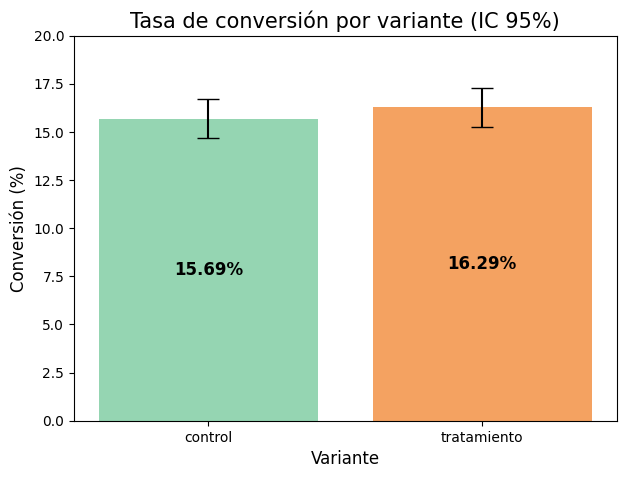

In [138]:
# La tasa de conversión con intervalo de confianza:

grupos = ["control", "tratamiento"]
tasas = [tabla_grupos.loc[g, "tasa"] * 100 for g in grupos]
errores = [1.96 * np.sqrt(tabla_grupos.loc[g, "tasa"] * (1 - tabla_grupos.loc[g, "tasa"])
                          / tabla_grupos.loc[g, "usuarios"]) * 100 for g in grupos]

plt.figure(figsize=(7, 5))
barras = plt.bar(grupos, tasas, yerr=errores, capsize=8, color=["#95D5B2", "#F4A261"])

for barra, tasa in zip(barras, tasas):
    plt.text(barra.get_x() + barra.get_width() / 2, tasa / 2, f"{tasa:.2f}%",
             ha="center", va="center", fontsize=12, fontweight="bold")

plt.title("Tasa de conversión por variante (IC 95%)", fontsize=15)
plt.xlabel("Variante", fontsize=12)
plt.ylabel("Conversión (%)", fontsize=12)
plt.ylim(0, 20)
plt.show()

Las tasas de conversión de control (15.69%) y tratamiento (16.29%) son similares y sus intervalos de confianza al 95% se solapan. El test z (α = 0.05, p = 0.4161) y el intervalo de la diferencia [-0.84, 2.03] pp, que incluye el 0, indican que no hay evidencia estadística de que la nueva UI modifique la conversión.

No rechazar H₀ no demuestra que ambas UI sean iguales: significa que con estos datos no se detectó un efecto.

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

# Informe ejecutivo

*Periodo analizado: 1 de enero al 29 de junio de 2025. Las métricas de rentabilidad usan 24.778 pedidos con costo conocido.*

## 1. Hallazgos clave
- **El negocio es rentable** en el periodo, incluso después de descontar marketing.
- **Marketing es la partida que más pesa:** equivale a cerca del 30% del ingreso y a casi la mitad del profit bruto.
- **En el funnel**, la mayor pérdida ocurre entre `begin_checkout` y `add_payment_info`: se pierden 958 usuarios (13,29%).
- **La retención semanal es estable** (entre ~40% y ~44%) en todas las cohortes de registro.
- **El cambio de UI del checkout no mostró un efecto estadísticamente significativo** (p = 0,4161).
- **Las ventas están repartidas de forma pareja** entre categorías (~33% del ingreso cada una). Hogar y Moda venden más unidades que Electrónica.

## 2. Métricas principales
| Métrica | Valor |
|---|---|
| Ingreso | 9.561.683,99 |
| Costo de producto | 3.808.530,76 |
| Profit bruto (margen ≈ 60%) | 5.753.153,23 |
| Inversión en marketing | 2.871.843,53 |
| **Profit final (margen ≈ 30%)** | **2.881.309,70** |
| Ticket promedio por orden | 385,89 |
| Cantidad promedio por orden | 1,5 unidades |
| Conversión final del funnel | 80,04% (6.240 de 7.796 usuarios) |
| Retención semanas 1 a 3 | ~40% a ~44% |
| Conversión control vs. tratamiento | 15,69% vs. 16,29% (dif. 0,60 pp; IC 95%: -0,84 a 2,03 pp) |

## 3. Insights accionables
- **El paso de checkout a información de pago concentra la mayor caída** del funnel, tanto en usuarios como en porcentaje. Es el primer lugar donde conviene investigar.
- **El gasto de marketing está repartido casi por igual entre canales** (social 976.818; organic 972.650; paid_search 922.374), pero los datos no permiten medir el retorno de cada canal, porque marketing y pedidos solo se relacionan por fecha.
- **La nueva UI no se puede declarar ni mejor ni peor.** La diferencia observada es compatible con el azar, y el intervalo de confianza incluye tanto efectos negativos como positivos.
- **La retención no muestra tendencia** entre cohortes: ni mejora ni empeora de enero a mayo.

## 4. Recomendaciones estratégicas
1. **Revisar el paso de pago del checkout** (campos, métodos de pago, errores) antes de hacer otros cambios en el funnel.
2. **Registrar el canal o la campaña en cada pedido**, para poder calcular el retorno de marketing por canal y decidir dónde invertir.
3. **Extender el experimento de la UI** o repetirlo con más usuarios antes de decidir, y definir de antemano el efecto mínimo que se quiere detectar.
4. **Dar seguimiento a la retención** con cohortes más largas (el análisis llega solo hasta la semana 3) para ver si hay abandono posterior.

## Limitaciones
- Las cifras corresponden al dataset limpio: se excluyeron duplicados, 4 pedidos con cantidad negativa, 10 con cantidades extremas, 50 sin cantidad y 30 con producto "Sin dato".
- Marketing no tiene registro del 30 de junio, por lo que el periodo se limitó al 29.
- El precio de venta no varía por producto mientras que los costos del catálogo sí, por lo que los márgenes por producto no son realistas (por ejemplo, Laptop-Gaming-16GB sale con profit negativo). No deben usarse para decidir sobre productos.
- El profit solo incluye costo de producto y marketing; no considera logística, personal ni otros gastos.
- YoY no se puede calcular: los datos cubren solo enero a junio de 2025.

---

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

In [141]:
# Link tableau public:
# https://public.tableau.com/app/profile/angela.arias3765/viz/PROYECTO_FINAL_ANGELA_ARIAS/Overview